c:\users\au646858\onedrive - aarhus universitet\documents\repositories\anemone\src\anemone\experiment\experiment.py:7: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.x = torch.tensor(x, dtype=torch.float64)
c:\users\au646858\onedrive - aarhus universitet\documents\repositories\anemone\src\anemone\experiment\experiment.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.y = torch.tensor(y, dtype=torch.float64)
c:\users\au646858\onedrive - aarhus universitet\documents\repositories\anemone\src\anemone\experiment\experiment.py:9: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True),

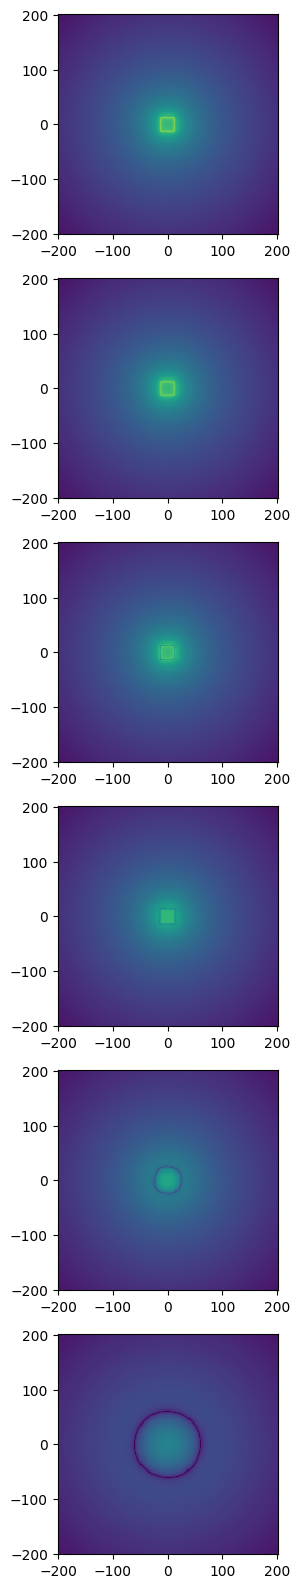

In [3]:
from anemone.experiment import Loop, Receiver
from anemone.forwards import ForwardFD
import torch
import matplotlib.pyplot as plt


lp = Loop.square(25)
freqs = torch.tensor([2000], dtype=torch.double)

rho = 40
sigma = 1/torch.tensor([rho,2*rho])
thick = torch.tensor([10])


zvals = torch.logspace(-1, 1.5, 6)
fig,ax = plt.subplots(len(zvals),1,figsize=(5,20))

for i,z in enumerate(zvals):
    rx = Receiver(x=torch.linspace(-200, 200, 202), y=torch.linspace(-200, 200, 202), z=z)

    fwr = ForwardFD(lp, rx, freqs)
    B = fwr(sigma, thick)

    ax[i].pcolormesh(rx.x,rx.y, torch.log10(torch.abs(B.reshape((202,202)))), vmin=-12, vmax=-5)
    ax[i].set_aspect('equal')

In [4]:
import matplotlib.pyplot as plt
import numpy as np

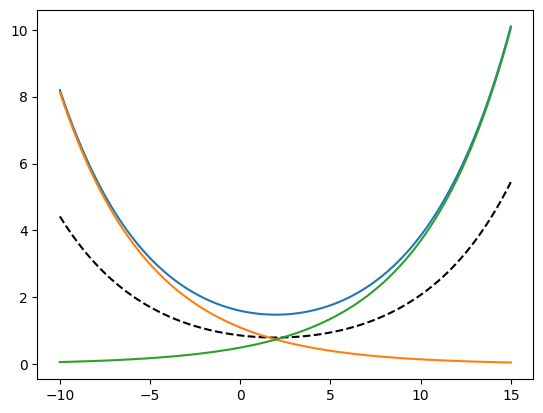

In [5]:
z = np.linspace(-10,15, 101)
u = 0.2
A = 1.1
B = 0.5

z_min = (0.5/u)*np.log(A/B)

plt.figure()
plt.plot(z, A*np.exp(-u*z)+B*np.exp(u*z))
plt.plot(z, 0.5*(A+B)*np.cosh(u*(z-z_min)), 'k--')
plt.plot(z, A*np.exp(-u*z))
plt.plot(z, B*np.exp(u*z))

In [6]:
from anemone.physics import *
from anemone import constants as c
import torch
import matplotlib.pyplot as plt
import numpy as np

In [7]:
# this is almost working, but the reflection coefficient in the air/ground interface is was going to 1/2 and not 0
# def transverse_electric_field_coefficients(sigma, thickness, omega, wave_length, mu=c.mu0, epsilon=c.epsilon0):
#     """ for computing the field components at depth
#     """
#     if isinstance(mu, float):
#         mu = torch.ones_like(sigma, dtype=torch.complex128, device=sigma.device)*mu
#     if isinstance(epsilon, float):
#         epsilon = torch.ones_like(sigma, dtype=torch.complex128, device=sigma.device)*epsilon

#     n_layers=len(sigma)

#     lambda2 = wave_length**2
    
#     u0 = torch.sqrt(lambda2 - omega**2 * c.mu0*c.epsilon0 + 0j)
    
#     k2 = calc_wavenumber(sigma, omega, mu=mu, epsilon=epsilon, sqrt=False)

#     # this is u_n (misnamed temporarily, will divide by zn soon.)
#     u_n = torch.sqrt(lambda2 - k2)
#     euh_p = torch.exp(u_n[:-1]*thickness)
#     euh_m = 1./euh_p

#     Amat = torch.zeros(u0.squeeze().shape+(2*n_layers-2, 2*n_layers-2), dtype=torch.complex128, device=sigma.device)
#     Bmat = torch.zeros((2*n_layers-2,), dtype=torch.complex128, device=sigma.device)
#     Bmat[0] = 1.

#     Amat[..., 0,0], Amat[..., 0,1], Amat[..., 0,2] = 1., -1., -1.
#     Amat[..., 1,0], Amat[..., 1,1], Amat[..., 1,2] = 0., u_n[0], -u_n[0]
    
#     for i in range(1,n_layers-2):
#         Amat[..., i*2,i*2-1] = euh_m[i-1]
#         Amat[..., i*2,i*2  ] = euh_p[i-1]
#         Amat[..., i*2,i*2+1] = -1.
#         Amat[..., i*2,i*2+2] = -1.


#         Amat[..., i*2+1,i*2-1] = -u_n[i-1]*euh_m[i-1]
#         Amat[..., i*2+1,i*2  ] =  u_n[i-1]*euh_p[i-1]
#         Amat[..., i*2+1,i*2+1] = -u_n[i]
#         Amat[..., i*2+1,i*2+2] =  u_n[i]

#     i = n_layers-2
#     Amat[..., i*2,i*2-1] = euh_m[i-1]
#     Amat[..., i*2,i*2  ] = euh_p[i-1]
#     Amat[..., i*2,i*2+1] = -1.


#     Amat[..., i*2+1,i*2-1] = -u_n[i-1]*euh_m[i-1]
#     Amat[..., i*2+1,i*2  ] =  u_n[i-1]*euh_p[i-1]
#     Amat[..., i*2+1,i*2+1] = -u_n[i]

#     AB = torch.linalg.solve(Amat, Bmat)
#     return AB[..., ::2], AB[..., 1::2]#, u_n

In [8]:
def transverse_electric_field_coefficients(sigma, thickness, omega, wave_length, mu=c.mu0, epsilon=c.epsilon0):
    """ for computing the field components at depth
        the size of the matrix can and should be reduced by 2.
        There are 2*n_layers of equations, but parameters in the first and last layers are known and can therefore be simplified.

    """
    if isinstance(mu, float):
        mu = torch.ones_like(sigma, dtype=torch.complex128, device=sigma.device)*mu
    if isinstance(epsilon, float):
        epsilon = torch.ones_like(sigma, dtype=torch.complex128, device=sigma.device)*epsilon

    n_layers=len(sigma)

    lambda2 = wave_length**2
    
    u0 = torch.sqrt(lambda2 - omega**2 * c.mu0*c.epsilon0 + 0j)
    
    k2 = calc_wavenumber(sigma, omega, mu=mu, epsilon=epsilon, sqrt=False)

    u_n = torch.sqrt(lambda2 - k2)
    euh_p = torch.exp(u_n[:-1]*thickness)
    euh_m = 1./euh_p

    Amat = torch.zeros(u0.squeeze().shape+(2*n_layers, 2*n_layers), dtype=torch.complex128, device=sigma.device)
    Bmat = torch.zeros((2*n_layers,), dtype=torch.complex128, device=sigma.device)

    Amat[..., 0,0], Amat[..., 0,1], Amat[..., 0,2], Amat[..., 0,3] =  1.,  1.,    -1., -1.
    Amat[..., 1,0], Amat[..., 1,1], Amat[..., 1,2], Amat[..., 1,3] = -u0,  u0, u_n[0], -u_n[0]
    
    for i in range(1, n_layers-1):
        Amat[..., i*2,i*2]   = euh_m[i-1]
        Amat[..., i*2,i*2+1] = euh_p[i-1]
        Amat[..., i*2,i*2+2] = -1.
        Amat[..., i*2,i*2+3] = -1.


        Amat[..., i*2+1,i*2  ] = -u_n[i-1]*euh_m[i-1]
        Amat[..., i*2+1,i*2+1] =  u_n[i-1]*euh_p[i-1]
        Amat[..., i*2+1,i*2+2] =  u_n[i]
        Amat[..., i*2+1,i*2+3] = -u_n[i]

    Amat[..., -2,-1] = 1.
    Amat[..., -1, 0] = 1.

    Bmat[-1] = 1

    AB = torch.linalg.solve(Amat, Bmat)
    return AB[..., ::2], AB[..., 1::2]

In [34]:
sigma = 10**np.random.uniform(-2, 0, 5)
sigma = torch.from_numpy(sigma).to(torch.float64)
thick = torch.logspace(0.5, 2, len(sigma))[1:]
thick_z = torch.zeros(len(sigma)+1)
thick_z[1:-1] = thick
thick_z[-1] = thick[-1]

# omega = torch.tensor([2000], dtype=torch.float64)
# lamda = torch.tensor([0.1], dtype=torch.float64)

omega = torch.logspace(1,6, 101, dtype=torch.float64)
lamda = torch.logspace(-5,-1, 201, dtype=torch.float64)

sigma = sigma[:, None, None].to(torch.complex128)
thick = thick[:, None, None].to(torch.complex128)
# thick_z = thick_z[:,None, None].to(torch.complex128)
omega = omega[None, :, None].to(torch.complex128)
lamda = lamda[None, None, :].to(torch.complex128)


In [35]:
A,B = transverse_electric_field_coefficients(sigma, thick, omega, lamda)

In [36]:
rte = refl_transverse_electric(sigma, thick, omega, lamda)

In [37]:
thick.squeeze().shape

torch.Size([4])

In [38]:
zbounds = thick.squeeze().real
zbounds = torch.cumsum(zbounds, dim=0)

In [39]:
zbounds

tensor([  7.4989,  25.2817,  67.4514, 167.4514], dtype=torch.float64)

In [40]:
z_eval = torch.linspace(-20, zbounds.max()*1.1, 51)
print(z_eval)

tensor([-20.0000, -15.9161, -11.8321,  -7.7482,  -3.6643,   0.4197,   4.5036,
          8.5875,  12.6714,  16.7554,  20.8393,  24.9232,  29.0072,  33.0911,
         37.1750,  41.2590,  45.3429,  49.4268,  53.5107,  57.5947,  61.6786,
         65.7625,  69.8465,  73.9304,  78.0143,  82.0983,  86.1822,  90.2661,
         94.3501,  98.4340, 102.5179, 106.6019, 110.6858, 114.7697, 118.8536,
        122.9376, 127.0215, 131.1054, 135.1894, 139.2733, 143.3572, 147.4412,
        151.5251, 155.6090, 159.6929, 163.7769, 167.8608, 171.9447, 176.0287,
        180.1126, 184.1965])


In [41]:
thick_z[0] = z_eval[0]

In [42]:
thick.shape

torch.Size([4, 1, 1])

In [43]:
zpos = (thick_z[:, None]*z_disc[None,:]).flatten()

NameError: name 'z_disc' is not defined

In [44]:
plt.figure()
plt.plot(zpos)

NameError: name 'zpos' is not defined

<Figure size 640x480 with 0 Axes>

In [45]:
zpos.shape

NameError: name 'zpos' is not defined

In [46]:
zpos.shape

NameError: name 'zpos' is not defined

In [47]:
A.flatten()[0]

tensor(1.+0.j, dtype=torch.complex128)

In [48]:
rte0 = -rte
rteN = -B[..., 0]

C:\Users\au646858\AppData\Local\Temp\ipykernel_11752\2611042960.py:6: RuntimeWarning: divide by zero encountered in log10
  pcm = axs[2].pcolor(np.log10(np.abs((rteN.real.squeeze()-rte0.real.squeeze())/rte0.real.squeeze())), vmin=-6, vmax=-1)
C:\Users\au646858\AppData\Local\Temp\ipykernel_11752\2611042960.py:7: MatplotlibDeprecationWarning: Getting the array from a PolyQuadMesh will return the full array in the future (uncompressed). To get this behavior now set the PolyQuadMesh with a 2D array .set_array(data2d).
  plt.colorbar(pcm, ax=axs[2])


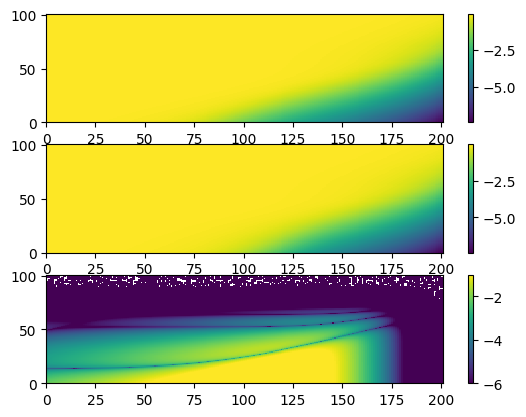

In [56]:
fig,axs = plt.subplots(3,1)
pcm = axs[0].pcolor(np.log10(rteN.real.squeeze()))
plt.colorbar(pcm, ax=axs[0])
pcm = axs[1].pcolor(np.log10(rte0.real.squeeze()))
plt.colorbar(pcm, ax=axs[1])
pcm = axs[2].pcolor(np.log10(np.abs((rteN.real.squeeze()-rte0.real.squeeze())/rte0.real.squeeze())), vmin=-6, vmax=-1)
plt.colorbar(pcm, ax=axs[2])

C:\Users\au646858\AppData\Local\Temp\ipykernel_11752\793717044.py:2: RuntimeWarning: invalid value encountered in log10
  pcm = axs[0].pcolor(np.log10(rteN.imag.squeeze()))#, vmin=0, vmax=1)
C:\Users\au646858\AppData\Local\Temp\ipykernel_11752\793717044.py:3: MatplotlibDeprecationWarning: Getting the array from a PolyQuadMesh will return the full array in the future (uncompressed). To get this behavior now set the PolyQuadMesh with a 2D array .set_array(data2d).
  plt.colorbar(pcm, ax=axs[0])
C:\Users\au646858\AppData\Local\Temp\ipykernel_11752\793717044.py:4: RuntimeWarning: invalid value encountered in log10
  pcm = axs[1].pcolor(np.log10(rte0.imag.squeeze()))#, vmin=0, vmax=1)
C:\Users\au646858\AppData\Local\Temp\ipykernel_11752\793717044.py:5: MatplotlibDeprecationWarning: Getting the array from a PolyQuadMesh will return the full array in the future (uncompressed). To get this behavior now set the PolyQuadMesh with a 2D array .set_array(data2d).
  plt.colorbar(pcm, ax=axs[1])
C:\U

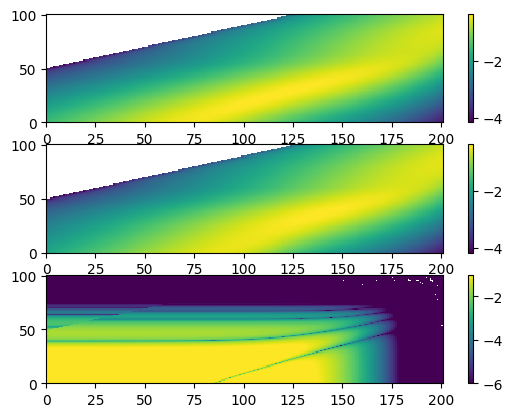

In [57]:
fig,axs = plt.subplots(3,1)
pcm = axs[0].pcolor(np.log10(rteN.imag.squeeze()))#, vmin=0, vmax=1)
plt.colorbar(pcm, ax=axs[0])
pcm = axs[1].pcolor(np.log10(rte0.imag.squeeze()))#, vmin=0, vmax=1)
plt.colorbar(pcm, ax=axs[1])
pcm = axs[2].pcolor(np.log10(np.abs((rteN.imag.squeeze()-rte0.imag.squeeze())/rte0.imag.squeeze())), vmin=-6, vmax=-1)
plt.colorbar(pcm, ax=axs[2])

In [3]:
from anemone.forwards import Forward

class ForwardFD(Forward):
    def __init__(self, source, receiver, freqs, waveform=None, filterfunc=None, tolerance=None):
        self.source = source
        self.receiver = receiver
        self.freqs = freqs if isinstance(freqs, torch.Tensor) else torch.tensor(freqs)
        self.device = freqs.device
        self.rmin = self.source.min_horizontal_distance(self.receiver).to(freqs.device)
        self.rmax = self.source.max_horizontal_distance(self.receiver).to(freqs.device)
        self.srcz = torch.tensor([source.z[0]], dtype=torch.float64)
        self.rz = self.receiver.z.flatten()[0]
        self.pfield_dz = torch.abs(self.srcz-self.rz)#[:, None, None]
        self.sfield_dz = torch.abs(self.srcz)+torch.abs(self.rz)#[:, None, None]

        self.filterfunc = filterfunc
        self.waveform = waveform
        self.tolerance=tolerance
        if self.device is not None:
            for attr_name in self.__dict__:
                attr_value = getattr(self, attr_name)
                if torch.is_tensor(attr_value):
                    setattr(self, attr_name, attr_value.to(self.device))      

    def forward(self):
        def frq_integrand(f):
            omega = c.twopi*f[:,None]

            def wvlngth_integrand(wave_length):
                """ Hz from horizontal electric dipole. """
                lmb = wave_length[None, :]
                
                tmp_u0 = u0(omega, lmb)
                A,B = transverse_electric_field_coefficients(self.sigma, self.thick, omega, lmb)
                
                intg = torch.exp(-tmp_u0*self.pfield_dz)+rte(self.sigma, self.thick, omega, lmb)*torch.exp(-tmp_u0*self.sfield_dz)
                intg *= lmb**2 / tmp_u0
            
                if self.filterfunc is not None:
                    intg *= self.filterfunc.omega_filter(omega)
                return torch.squeeze(intg/c.fourpi)
            
            hkl1 = Hankel(wvlngth_integrand, 1, range=(self.rmin, self.rmax), device=self.device, tolerance=self.tolerance)
            res = integrate_around_loop(self.source, self.receiver, hkl1)
            if self.waveform is not None:
                res /= -1j*omega.squeeze()
            return res.squeeze()
        
        H = frq_integrand(self.freqs)

        if self.waveform is not None:
            return H*self.waveform.fourier_d2wdt2(self.freqs)
        else:
            return H